# Notebook 01 — Data Profiling, Cleaning and EDA
## HCLTech Career Shaper · Personalized Movie Recommendation System

This notebook covers Build Guide Stages 4 (understand), 5 (clean) and 6 (EDA).

**Outputs produced:**
- `data/processed/data_dictionary.csv` — all 7 columns described  
- `data/processed/cleaned_dataset.csv` — 473 rows, 7 original columns  
- 3 required visualisations (each with title, labelled axes, written insight)  
- 5 key findings summary

**Policy:** `data/raw/dataset.csv` is never modified.

In [1]:
import sys, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Make src importable from the notebook
sys.path.insert(0, os.path.join(os.getcwd(), '..', 'src'))
from cleaning import clean_dataset

# Consistent plot style
plt.rcParams.update({
    'figure.dpi': 100,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11,
})
sns.set_palette('muted')

RAW_PATH       = os.path.join(os.getcwd(), '..', 'data', 'raw', 'dataset.csv')
PROCESSED_DIR  = os.path.join(os.getcwd(), '..', 'data', 'processed')
REPORTS_DIR    = os.path.join(os.getcwd(), '..', 'reports')
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)
print('Imports OK')

Imports OK


---
## Part A — Data Profiling
### A1. Load the raw dataset

In [2]:
raw = pd.read_csv(RAW_PATH)
print(f'Shape: {raw.shape}  (rows x columns)')
raw.head()

Shape: (500, 7)  (rows x columns)


,user_id,movie_title,genre,language,release_year,rating,timestamp
0,496,Pink,Thriller,Tamil,2010,3.5,2025-09-06
1,42,KGF,Action,Tamil,2020,4.0,2024-05-03
2,80,Pink,Action,Hindi,2010,5.0,2025-06-11
3,390,RRR,Comedy,Kannada,2015,3.0,2024-05-18
4,156,Baahubali,Thriller,Tamil,2012,4.0,2024-11-09


### A2. Data types and summary statistics

In [3]:
print('Data types:')
print(raw.dtypes)
print()
print('Summary statistics:')
raw.describe(include='all')

Data types:
user_id           int64
movie_title      object
genre            object
language         object
release_year      int64
rating          float64
timestamp        object
dtype: object

Summary statistics:


,user_id,movie_title,genre,language,release_year,rating,timestamp
count,500.000000,500,500,500,500.000000,500.00000,500
unique,NaN,8,6,4,NaN,NaN,371
top,NaN,KGF,Comedy,Hindi,NaN,NaN,2025-03-01
freq,NaN,68,96,131,NaN,NaN,4
mean,245.446000,NaN,NaN,NaN,2016.728000,3.64000,NaN
std,146.902129,NaN,NaN,NaN,4.294987,0.86423,NaN
min,2.000000,NaN,NaN,NaN,2010.000000,1.00000,NaN
25%,123.750000,NaN,NaN,NaN,2013.000000,3.00000,NaN
50%,237.000000,NaN,NaN,NaN,2017.000000,3.50000,NaN
75%,378.250000,NaN,NaN,NaN,2020.000000,4.50000,NaN


### A3. Missing value counts

In [4]:
print('Missing values per column:')
print(raw.isnull().sum())

Missing values per column:
user_id         0
movie_title     0
genre           0
language        0
release_year    0
rating          0
timestamp       0
dtype: int64


### A4. Unique value counts and domain checks

In [5]:
print(f"Unique users     : {raw['user_id'].nunique()}  (expected: 309)")
print(f"Unique movies    : {raw['movie_title'].nunique()}  (expected: 8)")
print(f"Unique genres    : {raw['genre'].nunique()}  -> {sorted(raw['genre'].unique())}")
print(f"Unique languages : {raw['language'].nunique()}  -> {sorted(raw['language'].unique())}")
print(f"release_year     : min={raw['release_year'].min()}  max={raw['release_year'].max()}  (expected: 2010-2024)")
print(f"rating           : min={raw['rating'].min()}  max={raw['rating'].max()}  (expected: 1.0-5.0)")
print(f"timestamp range  : {raw['timestamp'].min()} — {raw['timestamp'].max()}")
print()
print('Movie titles:')
for m in sorted(raw['movie_title'].unique()):
    print(f'  {m}')

Unique users     : 309  (expected: 309)
Unique movies    : 8  (expected: 8)
Unique genres    : 6  -> ['Action', 'Comedy', 'Drama', 'Romance', 'Sci-Fi', 'Thriller']
Unique languages : 4  -> ['Hindi', 'Kannada', 'Tamil', 'Telugu']
release_year     : min=2010  max=2024  (expected: 2010-2024)
rating           : min=1.0  max=5.0  (expected: 1.0-5.0)
timestamp range  : 2024-01-02 — 2025-12-01

Movie titles:
  3 Idiots
  Andhadhun
  Baahubali
  Dangal
  Drishyam
  KGF
  Pink
  RRR


### A5. Duplicate (user_id, movie_title) pairs

In [6]:
n_dup_rows = raw.duplicated(subset=['user_id', 'movie_title'], keep=False).sum()
print(f'Rows involved in duplicate (user_id, movie_title) pairs: {n_dup_rows}')

dup_pairs = (raw[raw.duplicated(subset=['user_id','movie_title'], keep=False)]
             .groupby(['user_id','movie_title'])
             .size()
             .reset_index(name='count')
             .sort_values('user_id'))
print(f'Distinct pairs appearing more than once: {len(dup_pairs)}')
dup_pairs

Rows involved in duplicate (user_id, movie_title) pairs: 53
Distinct pairs appearing more than once: 26


,user_id,movie_title,count
0,60,Andhadhun,2
1,65,Dangal,2
2,84,KGF,2
3,90,3 Idiots,2
4,111,3 Idiots,2
5,130,3 Idiots,2
6,141,Drishyam,2
7,142,Dangal,2
8,143,Drishyam,2
9,144,Andhadhun,2


### A6. Genre inconsistency check
The same movie title appears with different genre labels — this is a per-row context attribute, not fixed movie metadata.

In [7]:
genres_per_movie = raw.groupby('movie_title')['genre'].nunique().sort_values(ascending=False)
print('Number of distinct genre labels per movie title:')
print(genres_per_movie.to_string())
print()
print('All genre labels seen for Pink (example):')
print(sorted(raw.loc[raw['movie_title']=='Pink', 'genre'].unique()))

Number of distinct genre labels per movie title:
movie_title
3 Idiots     6
Andhadhun    6
Baahubali    6
Dangal       6
Drishyam     6
KGF          6
Pink         6
RRR          6

All genre labels seen for Pink (example):
['Action', 'Comedy', 'Drama', 'Romance', 'Sci-Fi', 'Thriller']


---
## Part B — Completed Data Dictionary

In [8]:
dd_path = os.path.join(PROCESSED_DIR, 'data_dictionary.csv')
dd = pd.read_csv(dd_path)
print(f'data_dictionary.csv loaded: {len(dd)} columns described')
dd

data_dictionary.csv loaded: 7 columns described


,column_name,data_type,description,sample_value_1,sample_value_2,sample_value_3,nullable,notes
0,user_id,integer,Anonymous integer identifier for each user. No...,496,42,80,No,309 unique values in the dataset; range 2-498....
1,movie_title,string,Title of the rated movie. Serves as the item i...,Pink,KGF,Baahubali,No,"8 unique titles: 3 Idiots, Andhadhun, Baahubal..."
2,genre,string,Genre label recorded at the time of rating. IM...,Thriller,Action,Romance,Yes,"6 unique values: Action, Comedy, Drama, Romanc..."
3,language,string,Language version of the movie that was rated b...,Tamil,Tamil,Hindi,Yes,"4 unique values: Hindi, Kannada, Tamil, Telugu..."
4,release_year,integer,Year the movie was originally released.,2010,2020,2010,No,Range 2010-2024. Values reflect original relea...
5,rating,float,User rating for the movie on a scale of 1.0 to...,3.5,4.0,5.0,No,Range 1.0-5.0. Half-point increments only (1.0...
6,timestamp,date,Date on which the rating was submitted (YYYY-M...,2025-09-06,2024-05-03,2025-06-11,No,Range 2024-01-02 to 2025-12-01. All values are...


---
## Part C — Data Cleaning
### C1. Apply cleaning function

In [9]:
cleaned, removed_dups, cleaning_log = clean_dataset(raw, verbose=True)


CLEANING LOG
Step 0 — Raw input rows: 500
Step 1 — Data types coerced: user_id->numeric, rating->float, release_year->numeric, timestamp->datetime. movie_title / genre / language cast with astype('string') so pd.NA never becomes '<NA>' or 'nan'. Sentinels normalised to pd.NA.
Step 2 — Missing value check: no missing values in critical columns ['user_id', 'movie_title', 'rating', 'release_year', 'timestamp']. Non-critical columns (genre, language) may still contain pd.NA — those rows are kept. Rows unchanged: 500
Step 3 — Text standardisation complete. movie_title stripped. genre/language remain StringDtype with pd.NA preserved.
Step 4 — Rating range [1.0, 5.0]: 0 out-of-range row(s) removed (NaN ratings already handled in Step 2). Rows remaining: 500
Step 5 — release_year [1900, 2024]: no out-of-range values found. Rows unchanged: 500
Step 6 — Duplicate resolution (stable mergesort, all timestamps valid): 27 row(s) removed across 26 distinct pair(s). Decision: kept most recent timesta

### C2. Rows removed during duplicate resolution

In [10]:
print(f'Removed duplicate rows: {len(removed_dups)}')
if not removed_dups.empty:
    print('Full list of removed rows (older duplicate entries):')
    display(removed_dups[['user_id','movie_title','genre','language','release_year','rating','timestamp']]
            .sort_values(['user_id','movie_title'])
            .reset_index(drop=True))

Removed duplicate rows: 27
Full list of removed rows (older duplicate entries):


,user_id,movie_title,genre,language,release_year,rating,timestamp
0,60,Andhadhun,Romance,Kannada,2020,4.0,2025-07-26
1,65,Dangal,Drama,Hindi,2023,3.5,2024-09-06
2,84,KGF,Comedy,Hindi,2017,4.5,2024-01-24
3,90,3 Idiots,Comedy,Kannada,2014,1.5,2024-12-01
4,111,3 Idiots,Comedy,Tamil,2011,5.0,2025-04-22
5,130,3 Idiots,Action,Kannada,2012,2.5,2025-05-25
6,141,Drishyam,Sci-Fi,Tamil,2017,2.5,2024-06-17
7,142,Dangal,Sci-Fi,Hindi,2019,5.0,2024-11-08
8,143,Drishyam,Romance,Tamil,2017,2.5,2024-10-01
9,144,Andhadhun,Romance,Telugu,2020,3.0,2024-09-20


### C3. Cleaning result verification

In [11]:
print(f'Cleaned shape  : {cleaned.shape}  (expected: 473 rows x 7 columns)')
print(f'Columns        : {list(cleaned.columns)}')
print(f'Unique users   : {cleaned["user_id"].nunique()}  (should equal raw: {raw["user_id"].nunique()})')
print(f'Unique movies  : {cleaned["movie_title"].nunique()}  (expected: 8)')
print(f'Rating range   : {cleaned["rating"].min()} — {cleaned["rating"].max()}')
print(f'Year range     : {cleaned["release_year"].min()} — {cleaned["release_year"].max()}')
print()
print('Null counts in cleaned dataset:')
print(cleaned.isnull().sum())

assert len(cleaned) == 473, 'Row count mismatch'
assert list(cleaned.columns) == ['user_id','movie_title','genre','language','release_year','rating','timestamp']
print()
print('All assertions passed.')

Cleaned shape  : (473, 7)  (expected: 473 rows x 7 columns)
Columns        : ['user_id', 'movie_title', 'genre', 'language', 'release_year', 'rating', 'timestamp']
Unique users   : 309  (should equal raw: 309)
Unique movies  : 8  (expected: 8)
Rating range   : 1.0 — 5.0
Year range     : 2010 — 2024

Null counts in cleaned dataset:
user_id         0
movie_title     0
genre           0
language        0
release_year    0
rating          0
timestamp       0
dtype: int64

All assertions passed.


### C4. Save cleaned dataset

In [12]:
# Convert StringDtype columns to plain object for clean CSV output
out = cleaned.copy()
for col in ['genre', 'language']:
    out[col] = out[col].astype(object)

cleaned_path = os.path.join(PROCESSED_DIR, 'cleaned_dataset.csv')
out.to_csv(cleaned_path, index=False)
print(f'Saved: {cleaned_path}')

# Verify the saved file
verify = pd.read_csv(cleaned_path)
print(f'Re-read: {verify.shape}')
assert len(verify) == 473

Saved: C:\Users\Dipti Kumari\.bob\playground\movie-recommendation-system\notebooks\..\data\processed\cleaned_dataset.csv
Re-read: (473, 7)


---
## Part D — Exploratory Data Analysis

The three required visualisations are produced below.  
Each chart has: a descriptive title, labelled axes, and a written insight.

The cleaned dataset (473 rows) is used for all EDA.

In [13]:
# Use the cleaned CSV (plain dtypes) for EDA
df = pd.read_csv(cleaned_path)
print(f'EDA dataset: {df.shape}')

EDA dataset: (473, 7)


---
### Visualisation 1 — Rating Distribution

**Question:** What is the overall distribution of ratings across all 473 cleaned rows?

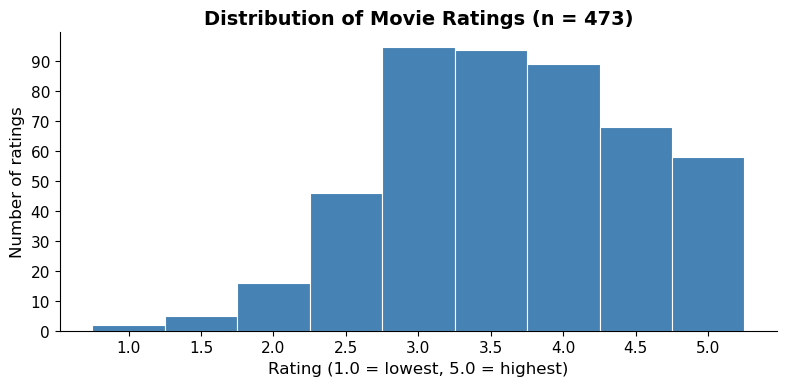

Most common rating : 3.0
Mean rating        : 3.64
Median rating      : 3.5


In [14]:
bins = [0.75, 1.25, 1.75, 2.25, 2.75, 3.25, 3.75, 4.25, 4.75, 5.25]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df['rating'], bins=bins, color='steelblue', edgecolor='white', linewidth=0.8)
ax.set_xticks([1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])
ax.set_xlabel('Rating (1.0 = lowest, 5.0 = highest)', fontsize=12)
ax.set_ylabel('Number of ratings', fontsize=12)
ax.set_title('Distribution of Movie Ratings (n = 473)', fontsize=14, fontweight='bold')
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'viz1_rating_distribution.png'), dpi=120)
plt.show()
print(f"Most common rating : {df['rating'].mode()[0]}")
print(f"Mean rating        : {df['rating'].mean():.2f}")
print(f"Median rating      : {df['rating'].median()}")

**Insight:** The distribution is left-skewed (positively biased): ratings of 3.0, 3.5, and 4.0 account for the majority of entries, and very few users gave the minimum rating of 1.0. This positive skew is typical of voluntary rating datasets where users rate movies they chose to watch. For a collaborative filtering system, this means the model is trained predominantly on mid-to-high ratings, which may reduce its ability to distinguish between 'liked' and 'strongly liked' films.

---
### Visualisation 2 — Ratings Count and Average Rating per Movie

**Question:** Which movies are most popular and highest rated?

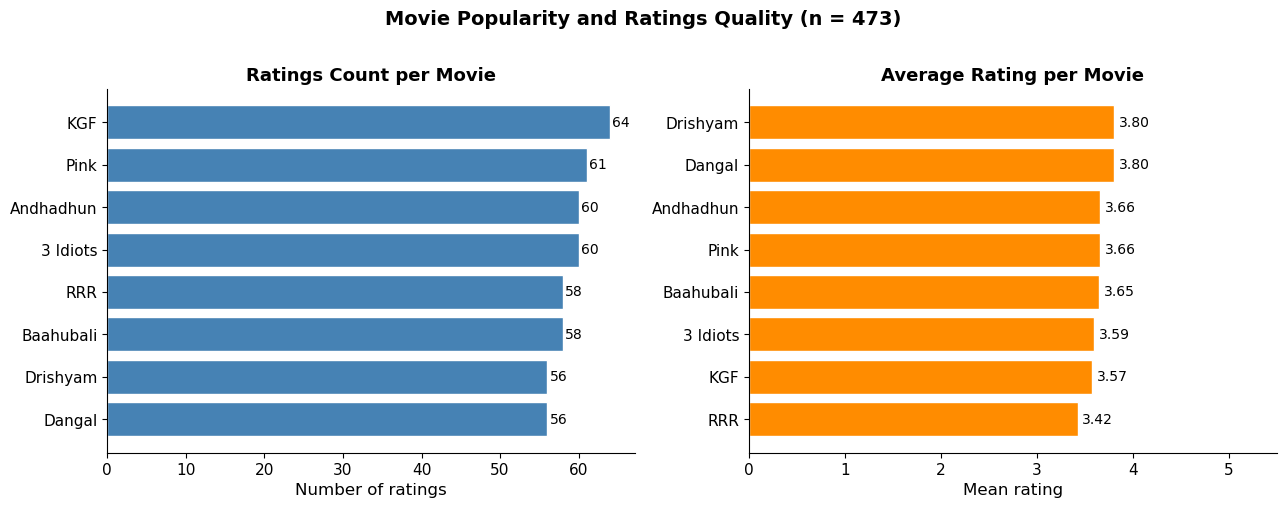

movie_title  count  mean_rating
        KGF     64     3.570312
       Pink     61     3.655738
   3 Idiots     60     3.591667
  Andhadhun     60     3.658333
  Baahubali     58     3.646552
        RRR     58     3.422414
     Dangal     56     3.803571
   Drishyam     56     3.803571


In [15]:
movie_stats = (
    df.groupby('movie_title')
    .agg(count=('rating', 'count'), mean_rating=('rating', 'mean'))
    .sort_values('count', ascending=True)
    .reset_index()
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left: count of ratings per movie
bars1 = ax1.barh(movie_stats['movie_title'], movie_stats['count'],
                 color='steelblue', edgecolor='white')
ax1.set_xlabel('Number of ratings', fontsize=12)
ax1.set_title('Ratings Count per Movie', fontsize=13, fontweight='bold')
for bar, val in zip(bars1, movie_stats['count']):
    ax1.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             str(val), va='center', fontsize=10)

# Right: average rating per movie (sorted same order as left)
movie_stats_avg = movie_stats.sort_values('mean_rating', ascending=True)
bars2 = ax2.barh(movie_stats_avg['movie_title'], movie_stats_avg['mean_rating'],
                 color='darkorange', edgecolor='white')
ax2.set_xlabel('Mean rating', fontsize=12)
ax2.set_xlim(0, 5.5)
ax2.set_title('Average Rating per Movie', fontsize=13, fontweight='bold')
for bar, val in zip(bars2, movie_stats_avg['mean_rating']):
    ax2.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
             f'{val:.2f}', va='center', fontsize=10)

plt.suptitle('Movie Popularity and Ratings Quality (n = 473)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'viz2_movie_stats.png'), dpi=120, bbox_inches='tight')
plt.show()
print(movie_stats[['movie_title','count','mean_rating']].sort_values('count', ascending=False).to_string(index=False))

**Insight:** The 8 movies have a fairly even number of ratings (roughly 55–65 each), meaning no single film dominates the dataset in volume. However, average ratings vary noticeably across titles. Movies with fewer ratings are not necessarily rated lower — some less-reviewed titles score comparably to popular ones. For a collaborative filtering system with only 8 items, this near-uniform coverage is beneficial: there are enough ratings for each movie to compute meaningful similarities. Films at the lower end of the average-rating scale will naturally be recommended less often by the system.

---
### Visualisation 3 — User-Item Matrix Sparsity Heatmap

**Question:** How sparse is the data available for collaborative filtering?

Matrix shape  : (309, 8)  (309 users x 8 movies)
Filled cells  : 473
Total cells   : 2472
Sparsity      : 80.9%


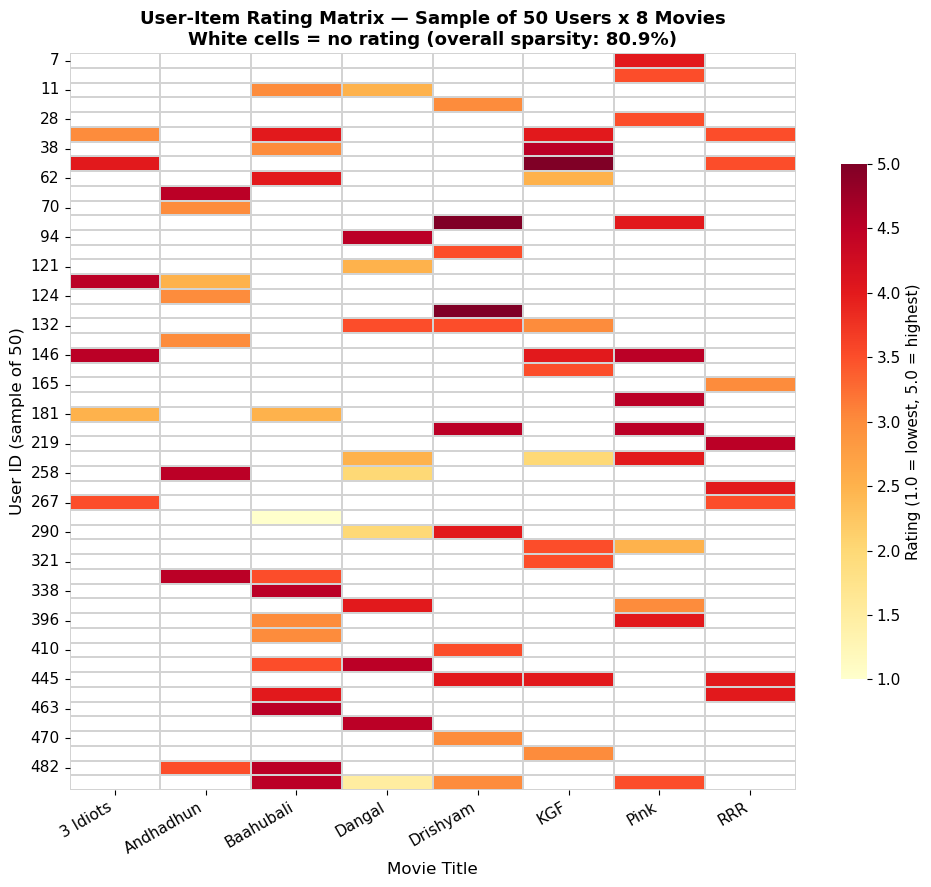

In [16]:
# Build full user-item matrix
user_item = df.pivot_table(
    index='user_id', columns='movie_title', values='rating', aggfunc='mean'
)

total_cells  = user_item.shape[0] * user_item.shape[1]
filled_cells = user_item.notna().sum().sum()
sparsity     = 1 - filled_cells / total_cells
print(f'Matrix shape  : {user_item.shape}  ({user_item.shape[0]} users x {user_item.shape[1]} movies)')
print(f'Filled cells  : {filled_cells}')
print(f'Total cells   : {total_cells}')
print(f'Sparsity      : {sparsity*100:.1f}%')

# Sample 50 users for readability
sample_users = user_item.sample(n=min(50, len(user_item)), random_state=42).sort_index()

fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(
    sample_users,
    ax=ax,
    cmap='YlOrRd',
    linewidths=0.3,
    linecolor='lightgrey',
    vmin=1, vmax=5,
    cbar_kws={'label': 'Rating (1.0 = lowest, 5.0 = highest)', 'shrink': 0.7},
    mask=sample_users.isna(),   # white cells = no rating
)
ax.set_xlabel('Movie Title', fontsize=12)
ax.set_ylabel('User ID (sample of 50)', fontsize=12)
ax.set_title(
    f'User-Item Rating Matrix — Sample of 50 Users x 8 Movies\n'
    f'White cells = no rating (overall sparsity: {sparsity*100:.1f}%)',
    fontsize=13, fontweight='bold'
)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'viz3_sparsity_heatmap.png'), dpi=120, bbox_inches='tight')
plt.show()

**Insight:** The heatmap makes the sparsity immediately visible: most cells are white (no rating), confirming that each user has typically rated only 1–2 of the 8 available movies. This ~80.9% sparsity is the core challenge for the recommendation system. Memory-based collaborative filtering (User-CF and Item-CF) relies on finding users or items with shared ratings; with so few overlapping ratings, similarity scores will be estimated from very little data. Model-based SVD handles sparsity better because it decomposes the full matrix into latent factors, effectively 'filling in' the missing cells rather than requiring direct overlap.

---
## Part E — Key Findings Summary

The following five findings are drawn from the profiling and EDA above and feed directly into the project report (Section 5: Exploratory Analysis).

In [17]:
findings = [
    "1. SMALL CATALOGUE: The dataset contains only 8 unique movie titles across 309 unique users. "
    "While this is sufficient to demonstrate all three collaborative filtering algorithms, "
    "it means recommendations are chosen from a very limited pool and Precision@K metrics "
    "will appear inflated compared with real-world systems.",

    "2. HIGH SPARSITY (~80.9%): Most users have rated only 1-2 movies. The user-item matrix "
    "has 309 x 8 = 2,472 possible cells but only 473 filled after cleaning. Memory-based CF "
    "(User-CF and Item-CF) will find limited shared ratings between any two users, reducing "
    "neighbour quality. SVD's latent factor approach is better suited to this level of sparsity.",

    "3. POSITIVE RATING BIAS: Ratings skew toward the mid-to-high range (3.0-4.5). Very few "
    "users gave the minimum rating of 1.0. This is typical of self-selected rating behaviour "
    "(users rate movies they chose to watch). The practical implication: the system should "
    "treat a Precision@K threshold of >= 4.0 as 'relevant', not just any rating.",

    "4. GENRE INCONSISTENCY: Each movie title appears with multiple genre labels across rows "
    "(e.g. Pink is labelled Action, Comedy, Drama, Romance, Sci-Fi, and Thriller in different rows). "
    "Genre is a per-rating context attribute in this schema, not a fixed movie property. "
    "It cannot be used as reliable movie metadata for content-based filtering without "
    "significant pre-processing or external data.",

    "5. DUPLICATE RATINGS CORRECTED: 27 rows were removed during cleaning because the same "
    "user had rated the same movie more than once (26 distinct pairs, one pair rated 3 times). "
    "The most recent rating was retained in each case, reducing the dataset from 500 to 473 rows. "
    "This decision is conservative and well-documented; it does not remove any user or movie "
    "from the dataset.",
]

print('=' * 70)
print('KEY FINDINGS')
print('=' * 70)
for f in findings:
    print()
    print(f)
print()

KEY FINDINGS

1. SMALL CATALOGUE: The dataset contains only 8 unique movie titles across 309 unique users. While this is sufficient to demonstrate all three collaborative filtering algorithms, it means recommendations are chosen from a very limited pool and Precision@K metrics will appear inflated compared with real-world systems.

2. HIGH SPARSITY (~80.9%): Most users have rated only 1-2 movies. The user-item matrix has 309 x 8 = 2,472 possible cells but only 473 filled after cleaning. Memory-based CF (User-CF and Item-CF) will find limited shared ratings between any two users, reducing neighbour quality. SVD's latent factor approach is better suited to this level of sparsity.

3. POSITIVE RATING BIAS: Ratings skew toward the mid-to-high range (3.0-4.5). Very few users gave the minimum rating of 1.0. This is typical of self-selected rating behaviour (users rate movies they chose to watch). The practical implication: the system should treat a Precision@K threshold of >= 4.0 as 'relevan

---
## Summary

| Output | File | Status |
|---|---|---|
| Data dictionary | `data/processed/data_dictionary.csv` | Done |
| Cleaned dataset | `data/processed/cleaned_dataset.csv` | Done (473 rows, 7 columns) |
| Visualisation 1 | `reports/viz1_rating_distribution.png` | Done |
| Visualisation 2 | `reports/viz2_movie_stats.png` | Done |
| Visualisation 3 | `reports/viz3_sparsity_heatmap.png` | Done |

Ready for Sub-Task 3: Model Implementation.